# 03 · Entrenamiento baseline
CNN desde cero. Guarda checkpoints en `experiments/<fecha>_<nombre>/` y reanuda solo si se interrumpe: basta con volver a ejecutar la celda de entrenamiento.

Hiperparámetros: `configs/baseline.yaml`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.train import load_config
cfg = load_config("configs/baseline.yaml")
RAW = cfg["data"]["raw_dir"]

I0000 00:00:1792862241.953581   20092 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
from src.train import train

run_dir = train("configs/baseline.yaml", name="baseline")  # resume=False para forzar corrida nueva

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1792862245.510294   20092 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9


Corrida: experiments/20261024-1217_baseline (nueva)
Epoch 1/30


I0000 00:00:1792862251.054765   48874 cuda_dnn.cc:461] Loaded cuDNN version 92700


952/952 - 177s - 185ms/step - accuracy: 0.4543 - loss: 1.7219 - val_accuracy: 0.6903 - val_loss: 0.9968 - learning_rate: 0.0010
Epoch 2/30
952/952 - 153s - 160ms/step - accuracy: 0.8867 - loss: 0.3338 - val_accuracy: 0.8559 - val_loss: 0.4780 - learning_rate: 0.0010
Epoch 3/30
952/952 - 152s - 160ms/step - accuracy: 0.9515 - loss: 0.1530 - val_accuracy: 0.8625 - val_loss: 0.4444 - learning_rate: 0.0010
Epoch 4/30
952/952 - 152s - 160ms/step - accuracy: 0.9700 - loss: 0.0940 - val_accuracy: 0.9191 - val_loss: 0.2820 - learning_rate: 0.0010
Epoch 5/30
952/952 - 155s - 162ms/step - accuracy: 0.9749 - loss: 0.0791 - val_accuracy: 0.9554 - val_loss: 0.1314 - learning_rate: 0.0010
Epoch 6/30
952/952 - 153s - 160ms/step - accuracy: 0.9841 - loss: 0.0512 - val_accuracy: 0.9709 - val_loss: 0.0905 - learning_rate: 0.0010
Epoch 7/30
952/952 - 151s - 159ms/step - accuracy: 0.9846 - loss: 0.0508 - val_accuracy: 0.9966 - val_loss: 0.0139 - learning_rate: 0.0010
Epoch 8/30
952/952 - 155s - 163ms/step

In [9]:
run_dir = sorted(Path("experiments").glob("*_baseline"))[-1]
print(run_dir)

experiments/20261024-1217_baseline


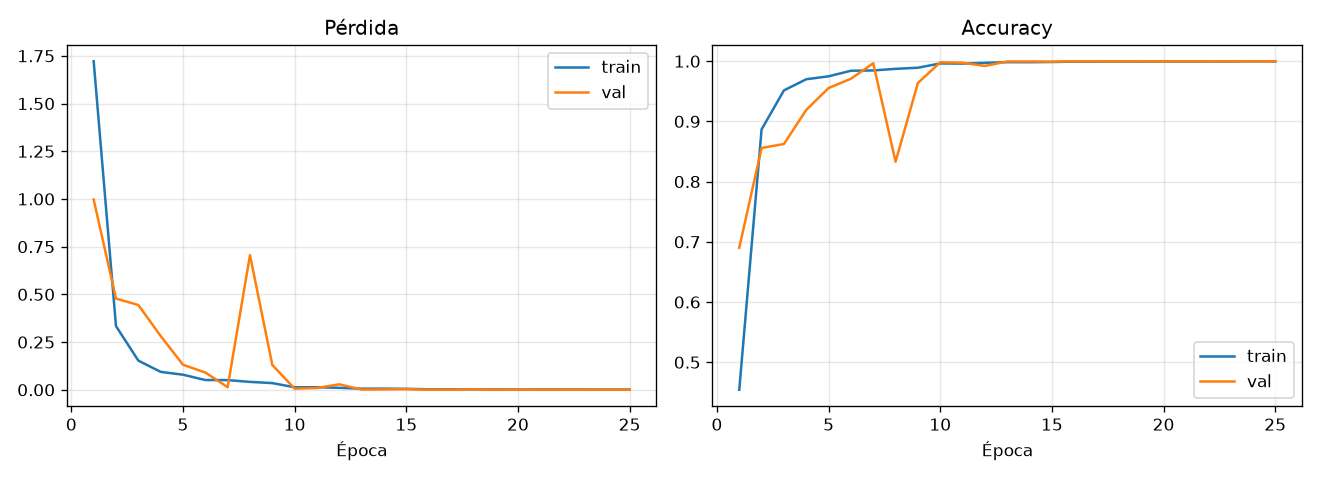

Accuracy en test: 1.0000


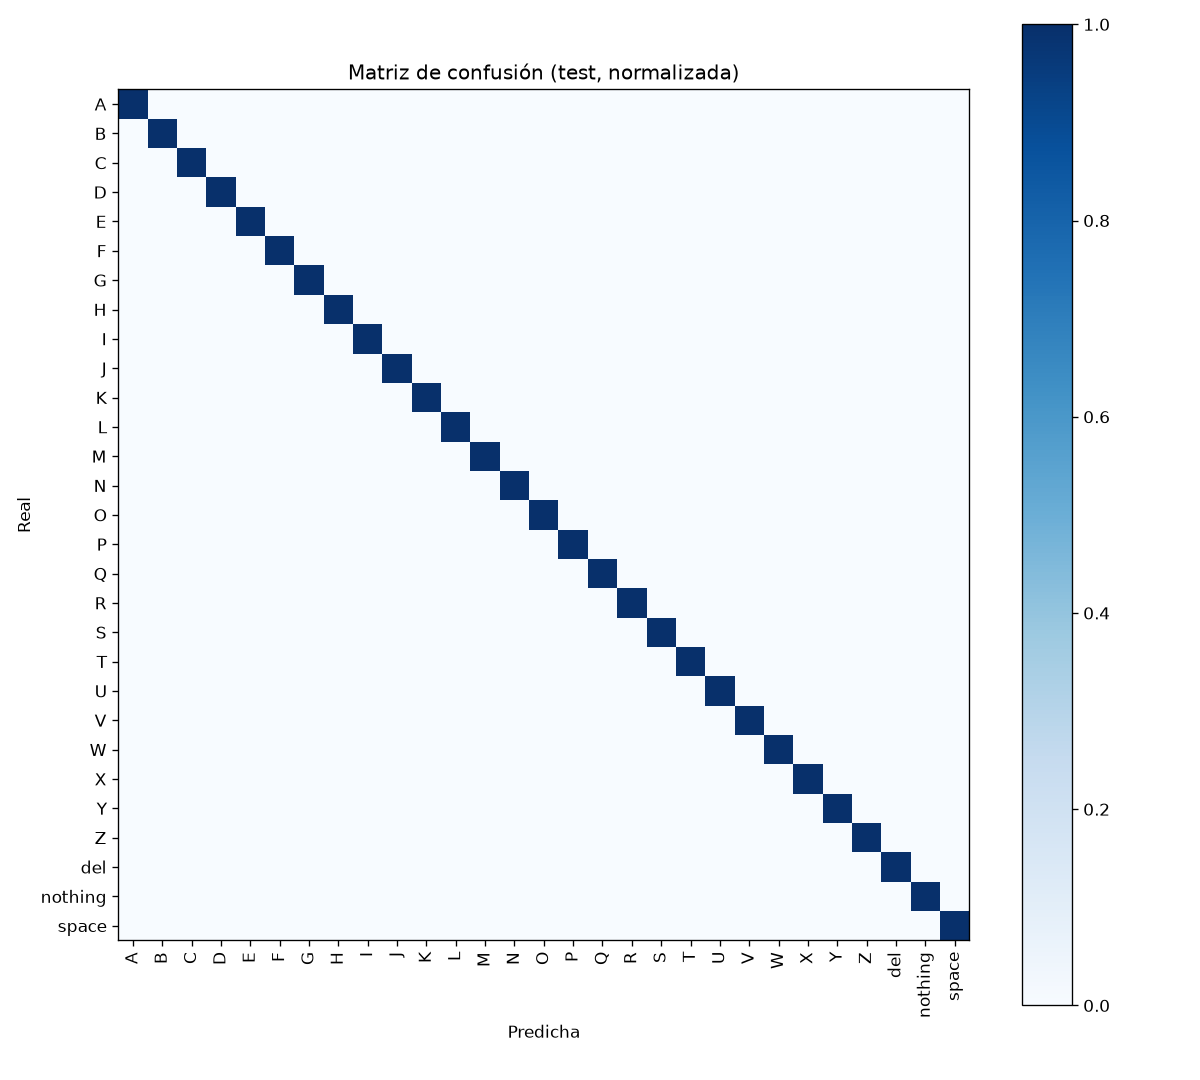

In [8]:
from IPython.display import Image, display
import json

display(Image(filename=str(run_dir / "curves.png")))
metrics = json.loads((run_dir / "metrics.json").read_text())
print(f"Accuracy en test: {metrics['accuracy']:.4f}")
display(Image(filename=str(run_dir / "confusion_matrix.png")))